In [21]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import xarray as xr
import math
from pathlib import Path

%cd /g/data/w42/dr6273/work/wind_drought/
import src.wind as wind
import src.utils as utils
import src.read as read
import src.meteorology as meteo

/g/data/w42/dr6273/work/wind_drought


In [22]:
import cartopy.crs as ccrs
import cartopy
cartopy.config['pre_existing_data_dir'] = '/g/data/w42/dr6273/work/data/cartopy-data/'
cartopy.config['data_dir'] = '/g/data/w42/dr6273/work/data/cartopy-data/'
from cartopy.mpl.ticker import LongitudeFormatter, LatitudeFormatter

In [23]:
%load_ext autoreload
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [24]:
wdd_dict = {}
for dataset in ["BARRA-R2"]:
    wdd_dict[dataset] = {}

    for variable in ["capacity_factor"]:
        wdd_dict[dataset][variable] = {}

        for region in ["NEM", "SE", "SWIS", "NWIS"]:
            
            if region in ["NEM", "SE"]:
                for scenario in ["SC30"]:
                    wdd_dict[dataset][variable][region+"-"+scenario] = {}

                    for averaging in ["weighted"]:
                        da = read.load_wind(dataset, variable, region, scenario, averaging)[variable]
                        pctl = utils.sel_month(da, [5, 6, 7]).quantile(0.1, "time")
                        wdd = wind.calc_wdd_timeseries(da, pctl)
                        
                        wdd_dict[dataset][variable][region+"-"+scenario][averaging] = wdd

            else:
                da = read.load_wind(dataset, variable, region)[variable]
                pctl = utils.sel_month(da, [5, 6, 7]).quantile(0.1, "time")
                wdd = wind.calc_wdd_timeseries(da, pctl)
                
                wdd_dict[dataset][variable][region] = wdd

# Compute drought events
events_dict = utils.map_leaves(
    wdd_dict,
    lambda value: wind.get_droughts(value)
)

# Obtain subset of longest droughts (>99th percentile) (discarding other droughts (95-99th percentile))
# subset_dict = utils.map_leaves(events_dict, wind.split_droughts)

In [25]:
def split_top(df):
    return {"top": wind.split_droughts(df)["top"]}

In [26]:
subset_dict = utils.map_leaves(events_dict, split_top)

n events: 516
low WDD thresh: 3.0 high WDD thresh: 5.0
n top events: 9 n other events: 40

n events: 553
low WDD thresh: 3.0 high WDD thresh: 5.0
n top events: 8 n other events: 39

n events: 515
low WDD thresh: 3.0 high WDD thresh: 3.0
n top events: 33 n other events: 0

n events: 634
low WDD thresh: 4.0 high WDD thresh: 6.0
n top events: 10 n other events: 23



In [27]:
utils.map_leaves(events_dict, wind.split_droughts)

n events: 516
low WDD thresh: 3.0 high WDD thresh: 5.0
n top events: 9 n other events: 40

n events: 553
low WDD thresh: 3.0 high WDD thresh: 5.0
n top events: 8 n other events: 39

n events: 515
low WDD thresh: 3.0 high WDD thresh: 3.0
n top events: 33 n other events: 0

n events: 634
low WDD thresh: 4.0 high WDD thresh: 6.0
n top events: 10 n other events: 23



{'BARRA-R2': {'capacity_factor': {'NEM-SC30': {'weighted': {'top':             WDD   end_date
     start_date                
     2010-05-13    9 2010-05-21
     1992-05-14    8 1992-05-21
     2008-05-08    6 2008-05-13
     2024-04-11    6 2024-04-16
     2024-05-21    6 2024-05-26
     1995-05-28    5 1995-06-01
     2001-05-01    5 2001-05-05
     2020-06-04    5 2020-06-08
     2010-07-20    5 2010-07-24,
     'other':             WDD   end_date
     start_date                
     1982-06-04    4 1982-06-07
     1982-07-08    4 1982-07-11
     1992-04-22    4 1992-04-25
     2006-07-23    4 2006-07-26
     2006-06-04    4 2006-06-07
     2001-06-29    4 2001-07-02
     2002-05-26    4 2002-05-29
     2001-07-20    4 2001-07-23
     2017-06-01    4 2017-06-04
     2025-06-26    4 2025-06-29
     2025-05-13    4 2025-05-16
     2021-04-26    4 2021-04-29
     2012-09-15    4 2012-09-18
     2017-04-12    4 2017-04-15
     2011-04-30    4 2011-05-03
     2010-05-31    4 2010-06-03


### Composite plots

In [10]:
def add_midpoints(levels, exclude_zero=False):
    levels = np.asarray(levels, dtype=float)

    new_levels = []

    for left, right in zip(levels[:-1], levels[1:]):
        new_levels.extend([left, (left + right) / 2])

    new_levels.append(levels[-1])

    new_levels = np.asarray(new_levels)

    if exclude_zero:
        new_levels = new_levels[new_levels != 0]

    return new_levels

In [11]:
def plot_sfc_barra(
    ax, da, tas_levels=[-6, -4, -2, 2, 4, 6], title="", add_quiver_key=False, composite=False
):
    """ Plot BARRA wind speed and direction, temperature anomalies and cloud cover """
    lats = da.lat.values
    lons = da.lon.values
    projection = ccrs.PlateCarree()

    # 2-m temperature anomalies
    if composite:
        tas_levels = add_midpoints(tas_levels)
        tas_levels = tas_levels[tas_levels != 0]
    t = da["tas"].plot.contourf(ax=ax, levels=tas_levels, zorder=0, add_colorbar=False)

    # Cloud cover
    cloud_levels = [75, 100]
    ax.contourf(
        lons,
        lats,
        da["clt"].rolling(lat=10, lon=10, center=True).mean().values,
        levels=cloud_levels,
        colors="#8C8C8C",
        alpha=0.35,
        transform=projection,
        zorder=2,
    )

    # Wind
    u_val = da["uas"].values
    v_val = da["vas"].values
    step = 20
    
    quiv = ax.quiver(
        lons[::step],
        lats[::step],
        u_val[::step, ::step],
        v_val[::step, ::step],
        transform=projection,
        color="k",
        scale=130,       # smaller value gives larger arrows
        width=0.006,
        zorder=5,
    )

    if add_quiver_key:
        ax.quiverkey(
            quiv,
            X=0.08,
            Y=-0.08,
            U=10,
            label="10 m s$^{-1}$",
            labelpos="E",
            coordinates="axes",
            fontproperties={"size": 8},
        )

    # MSLP
    (da["psl"] / 100).plot.contour(
        ax=ax,
        levels=np.arange(960, 1041, 5),
        colors="#303030",
        linewidths=1.2,
        # alpha=0.8,
        add_colorbar=False,
        zorder=3
    )

    ax.set_title(title, loc="left", fontsize=8)
    ax.coastlines(linewidth=0.6, zorder=4)
    # ax.set_extent([90, 180, 0, -49])
    ax.set_xlabel("")
    ax.set_ylabel("")

    return t

In [12]:
def plot_pl_era(
    ax, da, t850_levels=[-6, -4, -2, 2, 4, 6], title="", add_quiver_key=False, composite=False
):
    """ Plot ERA pressure-level diagnostics."""
    lats = da.lat.values
    lons = da.lon.values
    projection = ccrs.PlateCarree()

    # 850hPa temperature anomalies
    if composite:
        t850_levels = add_midpoints(t850_levels)
        t850_levels = t850_levels[t850_levels != 0]
    da["t850_anom"].plot.contourf(ax=ax, levels=t850_levels, zorder=0, add_colorbar=False)

    # Wind
    u_val = da["u850"].values
    v_val = da["v850"].values
    step = 5
    
    quiv = ax.quiver(
        lons[::step],
        lats[::step],
        u_val[::step, ::step],
        v_val[::step, ::step],
        transform=projection,
        color="k",
        scale=230,       # smaller value gives larger arrows
        width=0.006,
        zorder=5,
    )

    if add_quiver_key:
        qk = ax.quiverkey(
            quiv,
            X=0.08,
            Y=-0.08,
            U=20,
            label="20 m s$^{-1}$",
            labelpos="E",
            coordinates="axes",
            color="k",
            fontproperties={"size": 8},
        )

    # z500
    z500_levels = np.arange(4500, 6500, 200)

    da["z500"].plot.contour(
        ax=ax,
        levels=z500_levels,
        colors="#303030",
        linewidths=1.2,
        # alpha=0.8,
        add_colorbar=False,
        zorder=3
    )

    # z500 anomalies
    z500_anom_levels = np.arange(-800, 801, 100)
    if composite:
        z500_anom_levels = add_midpoints(z500_anom_levels)
    z500_anom_levels = z500_anom_levels[z500_anom_levels != 0]
    
    da["z500_anom"].plot.contour(
        ax=ax,
        levels=z500_anom_levels,
        colors="tab:pink",
        linewidths=1.6,
        # alpha=0.8,
        add_colorbar=False,
        zorder=3
    )

    # u300
    da["u300"].plot.contour(
        ax=ax,
        levels=[30, 40, 50, 60, 70],
        colors="tab:gray",
        linewidths=[0.8, 1.2, 1.6, 2.0, 2.0],
        transform=ccrs.PlateCarree(),
        add_colorbar=False,
    )

    ax.set_title(title, loc="left", fontsize=8)
    ax.coastlines(linewidth=0.6, zorder=4)
    ax.set_extent([90, 170, 0, -49])
    ax.set_xlabel("")
    ax.set_ylabel("")

In [13]:
def plot_event_maps(event_name, da_sfc, da_pl, days_before=0, days_after=2):
    """Plot composite maps followed by maps of the event sequence."""

    n_times = len(da_sfc.time)
    n_event_times = n_times - days_before - days_after
    times_per_row = 6

    # Composite excluding the final two days
    da_sfc_composite = da_sfc.isel(time=range(days_before, n_event_times - days_after)).mean("time")
    da_pl_composite = da_pl.isel(time=range(days_before, n_event_times - days_after)).mean("time")

    # One extra slot for the composite
    n_slots = n_times + 1 #n_event_times + 1
    n_time_rows = math.ceil(n_slots / times_per_row)

    fig, axes = plt.subplots(
        2 * n_time_rows,
        times_per_row,
        figsize=(18, 4.5 * n_time_rows),
        subplot_kw={"projection": ccrs.PlateCarree()},
        squeeze=False,
    )

    # Plot composite in slot 0
    p = plot_sfc_barra(
        axes[0, 0],
        da_sfc_composite,
        add_quiver_key=True
    )

    plot_pl_era(
        axes[1, 0],
        da_pl_composite,
        add_quiver_key=True
    )
    
    axes[0, 0].set_title("", loc="center")
    axes[0, 0].set_title("Composite mean", fontsize=8, loc="left")
    
    axes[1, 0].set_title("", loc="center")

    # Plot individual event days in slots 1 onward
    break_time = 1
    for time in range(n_times):
        slot = time + 1

        time_row = slot // times_per_row
        col = slot % times_per_row

        sfc_row = 2 * time_row
        pl_row = sfc_row + 1

        plot_sfc_barra(
            axes[sfc_row, col],
            da_sfc.isel(time=time),
        )

        plot_pl_era(
            axes[pl_row, col],
            da_pl.isel(time=time),
        )

        axes[sfc_row, col].set_title("", loc="center")
        
        if slot < n_times - 1:
            axes[sfc_row, col].set_title("Day " + str(time + 1), fontsize=8, loc="left")
            axes[pl_row, col].set_title("", loc="center")
        else:
            axes[sfc_row, col].set_title("Break day " + str(break_time), fontsize=8, loc="left")
            break_time += 1
            
        axes[pl_row, col].set_title("", loc="center")

    # Hide unused axes
    for slot in range(n_slots, n_time_rows * times_per_row):
        time_row = slot // times_per_row
        col = slot % times_per_row

        axes[2 * time_row, col].set_visible(False)
        axes[2 * time_row + 1, col].set_visible(False)

    # Row labels
    for time_row in range(n_time_rows):
        sfc_ax = axes[2 * time_row, 0]
        pl_ax = axes[2 * time_row + 1, 0]

        sfc_pos = sfc_ax.get_position()
        pl_pos = pl_ax.get_position()

        fig.text(
            sfc_pos.x0 - 0.01,
            (sfc_pos.y0 + sfc_pos.y1) / 2,
            "Surface",
            rotation=90,
            va="center",
            ha="center",
            fontsize=8,
        )

        fig.text(
            pl_pos.x0 - 0.01,
            (pl_pos.y0 + pl_pos.y1) / 2,
            "Troposphere",
            rotation=90,
            va="center",
            ha="center",
            fontsize=8,
        )

    # Shared colourbar
    cax = fig.add_axes([0.92, 0.35, 0.015, 0.3])

    cbar = fig.colorbar(
        p,
        cax=cax,
        orientation="vertical",
    )

    cbar.set_label("Temperature anomaly [K]")

    plt.savefig("figures/dynamics_"+region+"_"+event_name+".png", dpi=300)
    plt.close(fig)

    return fig, axes

In [20]:
subset_dict

NameError: name 'subset_dict' is not defined

In [19]:
day=10
print(f"{day:02d}")

10


In [15]:
root = "/g/data/ng72/dr6273/work/projects/wind_drought/plotting/wind_drought_composites/"

In [256]:
# Top droughts - each event
for region in list(droughts_subset.keys())[3:]:

    droughts_subset_sorted = (
        droughts_subset[region]["top"]
        .rename_axis("start_date")
        .reset_index()
        .sort_values(
            ["WDDx", "start_date"],
            ascending=[False, True],
        )
        .set_index("start_date")
    )
    
    for event_id in range(3)[:]:
        
        event_name = droughts_subset_sorted.iloc[event_id].name.strftime("%Y-%m-%d")
        print(event_name)
        
        da_sfc = xr.open_dataset(PLOT_DATA_PATH + "/sfc_barra/wddx_" + region + "_" + str(event_id) + "_" + event_name + ".nc")
        da_pl = xr.open_dataset(PLOT_DATA_PATH + "/pl_era/wddx_" + region + "_" + str(event_id) + "_" + event_name + ".nc")

        event_name = event_name + "_" + str(event_id)
        plot_event_maps(event_name, da_sfc, da_pl)

1999-05-15
2024-06-08
1988-06-15


In [196]:
from pathlib import Path

In [197]:
def get_composite(region, droughts, duration):
    """ Return composite array for droughts of a given duration"""
    # Start dates of events with this duration
    starts = droughts[droughts == duration].index

    sfc_events = []
    pl_events = []

    for start in starts:
        start_str = start.strftime("%Y-%m-%d")
        directory = Path(PLOT_DATA_PATH + "pl_era/")
        file = [path.name for path in directory.glob(f"*{region}*{start_str}*.nc")][0]

        da_sfc = xr.open_dataset(PLOT_DATA_PATH + "/sfc_barra/" + file)
        da_pl = xr.open_dataset(PLOT_DATA_PATH + "/pl_era/" + file)

        end = start + pd.Timedelta(days=int(duration))
        
        sfc_events.append(
            da_sfc.sel(time=slice(start, end))
        )

        pl_events.append(
            da_pl.sel(time=slice(start, end))
        )

    # Combine all event days into one time dimension
    da_sfc_length = xr.concat(sfc_events, dim="time")
    da_pl_length = xr.concat(pl_events, dim="time")
    n = len(da_sfc_length.time.values)

    # Calculate composite over all days and all events
    da_sfc_composite = da_sfc_length.mean("time")
    da_pl_composite = da_pl_length.mean("time")

    return (da_sfc_composite, da_pl_composite, n)

In [277]:
def plot_composites(events_df):
    """Plot composite maps as a function of event length."""

    durations = sorted(droughts.unique(), reverse=True)

    durations_per_row = 4
    n_duration_rows = math.ceil(len(durations) / durations_per_row)

    fig, axes = plt.subplots(
        2 * n_duration_rows,
        durations_per_row,
        figsize=(18, 6 * n_duration_rows),
        subplot_kw={"projection": ccrs.PlateCarree()},
        squeeze=False,
    )

    for i, duration in enumerate(durations):
    
        duration_row = i // durations_per_row
        col = i % durations_per_row
    
        sfc_row = 2 * duration_row
        pl_row = sfc_row + 1
    
        da_sfc_composite, da_pl_composite, n = get_composite(
            region,
            droughts,
            duration,
        )
    
        p = plot_sfc_barra(
            axes[sfc_row, col],
            da_sfc_composite,
            # composite=True
        )
    
        plot_pl_era(
            axes[pl_row, col],
            da_pl_composite,
            # composite=True
        )

        axes[sfc_row, col].set_title(
            f"{duration}-day events"+r" ($n=$"+str(n)+")",
            fontsize=8,
            loc="left",
        )
    
        # Remove automatic centre titles
        axes[sfc_row, col].set_title("", loc="center")
        axes[pl_row, col].set_title("", loc="center")
    
    # Hide unused axes
    for i in range(len(durations), n_duration_rows * durations_per_row):

        duration_row = i // durations_per_row
        col = i % durations_per_row
    
        axes[2 * duration_row, col].set_visible(False)
        axes[2 * duration_row + 1, col].set_visible(False)

    # Row labels
    for duration_row in range(n_duration_rows):
    
        sfc_ax = axes[2 * duration_row, 0]
        pl_ax = axes[2 * duration_row + 1, 0]
    
        sfc_pos = sfc_ax.get_position()
        pl_pos = pl_ax.get_position()
    
        fig.text(
            sfc_pos.x0 - 0.01,
            (sfc_pos.y0 + sfc_pos.y1) / 2,
            "Surface",
            rotation=90,
            va="center",
            ha="center",
            fontsize=8,
        )
    
        fig.text(
            pl_pos.x0 - 0.01,
            (pl_pos.y0 + pl_pos.y1) / 2,
            "Troposphere",
            rotation=90,
            va="center",
            ha="center",
            fontsize=8,
        )

    # Shared colourbar
    cax = fig.add_axes([0.92, 0.35, 0.015, 0.3])

    cbar = fig.colorbar(
        p,
        cax=cax,
        orientation="vertical",
    )

    cbar.set_label("Temperature anomaly [K]")

    # plt.savefig("figures/dynamics_"+region+"_"+event_name+".png", dpi=300)
    # plt.close(fig)

    return fig, axes

In [278]:
region = "nem-2030"
droughts = droughts_dfs[region]["WDDx"]

In [279]:
# Necessary until ERA5 data is updated to 2025
droughts = droughts[droughts.index.year < 2025]

(<Figure size 1800x1200 with 17 Axes>,
 array([[<GeoAxes: title={'left': '9-day events ($n=$9)'}>,
         <GeoAxes: title={'left': '8-day events ($n=$16)'}>,
         <GeoAxes: title={'left': '6-day events ($n=$6)'}>,
         <GeoAxes: title={'left': '5-day events ($n=$25)'}>],
        [<GeoAxes: >, <GeoAxes: >, <GeoAxes: >, <GeoAxes: >],
        [<GeoAxes: title={'left': '4-day events ($n=$28)'}>,
         <GeoAxes: title={'left': '3-day events ($n=$36)'}>,
         <GeoAxes: title={'left': '2-day events ($n=$26)'}>,
         <GeoAxes: title={'left': '1-day events ($n=$4)'}>],
        [<GeoAxes: >, <GeoAxes: >, <GeoAxes: >, <GeoAxes: >]], dtype=object))

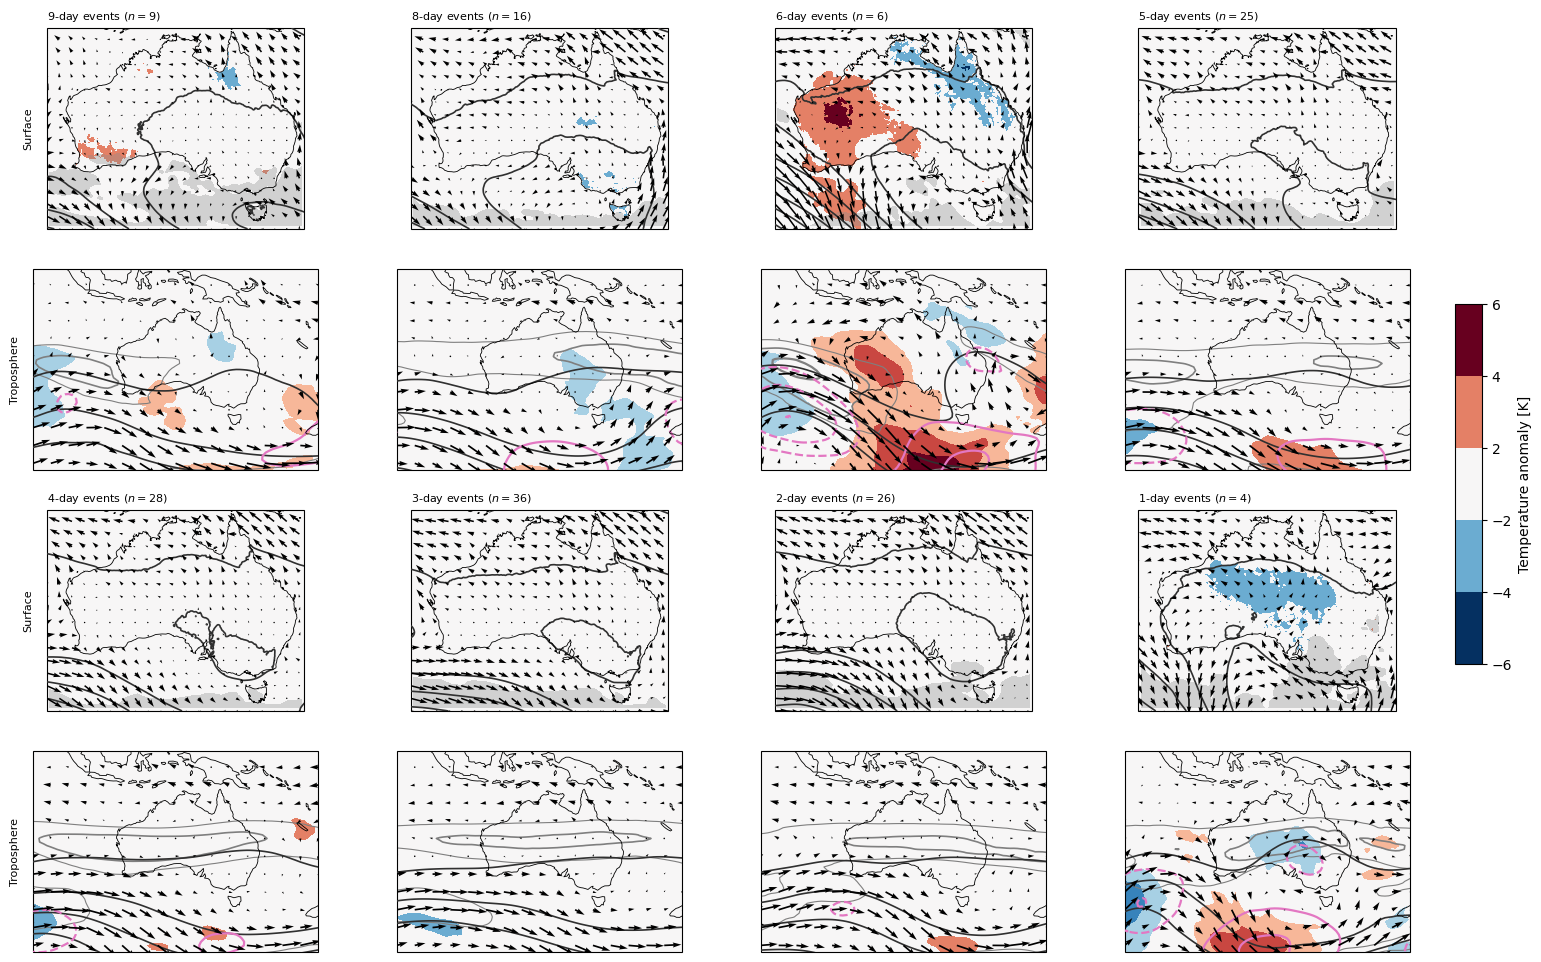

In [280]:
plot_composites(droughts)

In [89]:
import xclim as xc

def calc_wdd(timeseries, pctl10):
    """Calculate wind drought duration (WDDx) for a single timeseries"""

    calm_days = timeseries < pctl10
    drought_events = xc.indices.run_length.find_events(calm_days, window=1)
    drought_events = drought_events.assign_coords(
        time=('event', drought_events['event_start'].data)
    ).drop_vars('event_start')
    drought_events = drought_events.swap_dims({'event': 'time'}).dropna('time')
    # wddx_da = drought_events['event_length'].resample(time='1YS').max()
    # wddx_times = drought_events['event_length'].resample(time='1YS').map(xr.DataArray.idxmax, dim='time', keep_attrs=True)
    # wddx_da['time'] = wddx_times
    # wddx_ds = wddx_da.to_dataset()

    return drought_events

In [90]:
# wddx_obs = {}
# for r, da in obs_dict.items():
#     pctl10 = np.percentile(da['sfcWind'], 10)
#     print(pctl10)
#     wddx_obs[r] = utils.calc_wddx_obs(da, pctl10)

In [95]:
wdd = calc_wdd(obs_dict['nem-2030']['sfcWind'], np.percentile(obs_dict['nem-2030']['sfcWind'], 10)).event_length

(array([28., 13.,  0.,  5.,  1.,  0.,  0.,  2.,  1.]),
 array([3.        , 3.66666667, 4.33333333, 5.        , 5.66666667,
        6.33333333, 7.        , 7.66666667, 8.33333333, 9.        ]),
 <BarContainer object of 9 artists>)

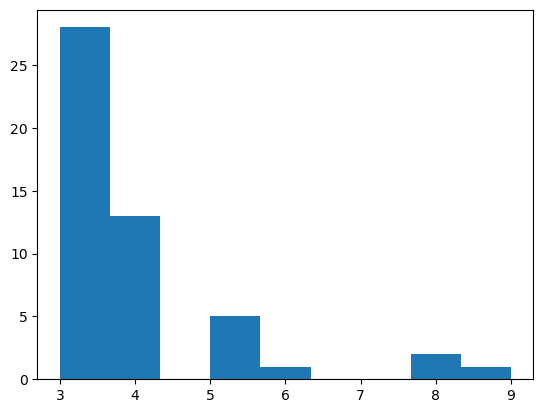

In [98]:
plt.hist(wdd.where(wdd > 2), bins=9)